## Level 1: Task 1 — Exploratory Data Analysis (EDA) on Retail Sales Data

### 1. Project Overview
This project focuses on analyzing retail sales data to identify sales trends, understand customer demographics, and evaluate product category performance using Python.

### 2. Objectives
- Inspect and clean the dataset.
- Calculate descriptive statistics.
- Analyze monthly and quarterly sales trends.
- Explore customer age and gender distributions.
- Identify top-performing product categories.
- Visualize correlations between numerical variables.
- Derive actionable business insights and recommendations.

### 3. Technologies Used
- Python: Data analysis and calculations.
- Pandas: Data loading, manipulation, and aggregation.
- NumPy: Numerical operations.
- Matplotlib: Data visualization.
- Seaborn: Statistical charts and correlation heatmaps.
- Jupyter Notebook: Interactive development and documentation.

### 4. Dataset Description
The dataset contains 1,000 retail transaction records and 9 original columns, including transaction date, customer age, gender, product category, quantity, price per unit, and total transaction amount.

### 5. Expected Outcome
To identify meaningful patterns in retail sales and customer purchasing behavior and provide recommendations to support inventory management, marketing, and sales planning.

In [1]:
from pathlib import Path

downloads = Path.home() / "Downloads"

csv_files = list(downloads.rglob("retail_sales_dataset.csv"))

print(csv_files)

[WindowsPath('C:/Users/ganes/Downloads/retail_sales_dataset.csv')]


In [2]:
import pandas as pd

df = pd.read_csv(csv_files[0])

display(df.head())

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [3]:
from pathlib import Path

csv_files = list(Path.home().rglob("retail_sales_dataset.csv"))

print(csv_files[:20])

[WindowsPath('C:/Users/ganes/Downloads/retail_sales_dataset.csv')]


In [4]:
df.describe()

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


In [5]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [6]:
#check number of rows and columns
print("Dataset Shape:",df.shape)

Dataset Shape: (1000, 9)


In [7]:
#Display all column names
print(df.columns.tolist())

['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 100.2 KB


In [9]:
#check missing values
df.isnull().sum()

Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

In [10]:
print("The Duplicate rows:",df.duplicated().sum()) 

The Duplicate rows: 0


In [11]:
df.head(7)

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100
5,6,2023-04-25,CUST006,Female,45,Beauty,1,30,30
6,7,2023-03-13,CUST007,Male,46,Clothing,2,25,50


In [12]:
# Select all numerical columns
numerical_df = df.select_dtypes(include="number")

# Calculate descriptive statistics
statistics = pd.DataFrame({
    "Mean": numerical_df.mean(),
    "Median": numerical_df.median(),
    "Mode": numerical_df.mode().iloc[0],
    "Standard Deviation": numerical_df.std()
})

# Display the results
display(statistics.round(2))

,Mean,Median,Mode,Standard Deviation
Transaction ID,500.50,500.5,1.0,288.82
Age,41.39,42.0,43.0,13.68
Quantity,2.51,3.0,4.0,1.13
Price per Unit,179.89,50.0,50.0,189.68
Total Amount,456.00,135.0,50.0,560.00


In [13]:
# Convert Date column to datetime format
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Check the updated data type
print("Date column data type:", df["Date"].dtype)

# Check for invalid dates
print("Invalid dates:", df["Date"].isna().sum())

Date column data type: datetime64[us]
Invalid dates: 0


In [14]:
# Make sure the Date column is in datetime format
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Group sales by month
monthly_sales = (
    df.dropna(subset=["Date"])
      .set_index("Date")["Total Amount"]
      .resample("MS")
      .sum()
)

# Display monthly sales
display(monthly_sales)

Date
2023-01-01    35450
2023-02-01    44060
2023-03-01    28990
2023-04-01    33870
2023-05-01    53150
2023-06-01    36715
2023-07-01    35465
2023-08-01    36960
2023-09-01    23620
2023-10-01    46580
2023-11-01    34920
2023-12-01    44690
2024-01-01     1530
Freq: MS, Name: Total Amount, dtype: int64

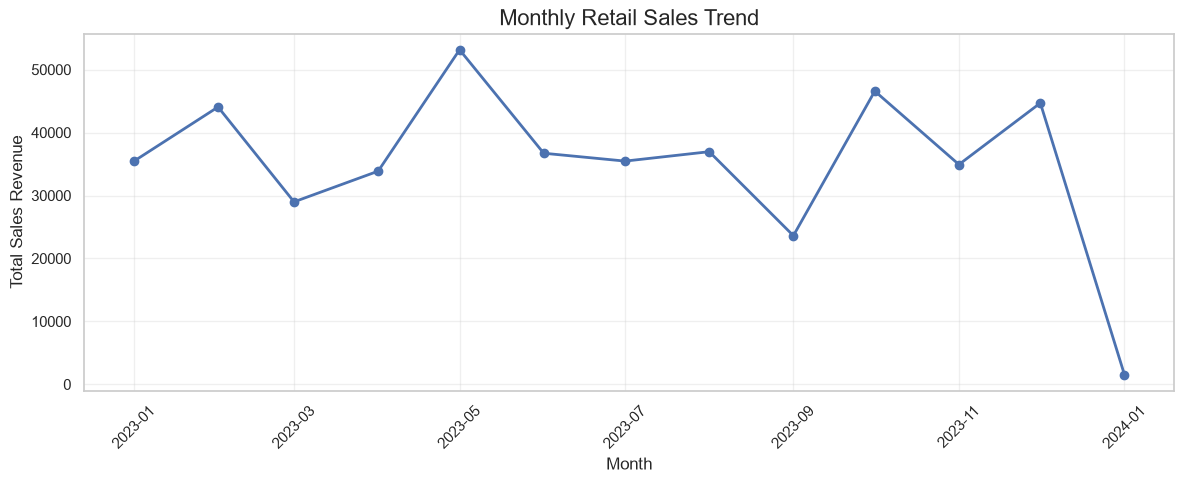

In [15]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Retail Sales Trend", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Total Sales Revenue")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

In [16]:
best_month = monthly_sales.idxmax()
lowest_month = monthly_sales.idxmin()

print("Highest sales month:", best_month.strftime("%B %Y"))
print("Highest monthly revenue:", monthly_sales.max())

print("Lowest sales month:", lowest_month.strftime("%B %Y"))
print("Lowest monthly revenue:", monthly_sales.min())

Highest sales month: May 2023
Highest monthly revenue: 53150
Lowest sales month: January 2024
Lowest monthly revenue: 1530


### Observation: Monthly Retail Sales Trend

The highest monthly sales were recorded in May 2023 (53,150), while the lowest occurred in January 2024 (1,530). This indicates significant variations in monthly revenue.

Recommendations:
1. Analyze the factors behind peak sales in May 2023.
2. Investigate the sales decline in January 2024.
3. Use sales trends to improve inventory planning and promotional campaigns.

In [17]:
quarterly_sales = (
    df.set_index("Date")["Total Amount"]
      .resample("QS")
      .sum()
)

display(quarterly_sales)

Date
2023-01-01    108500
2023-04-01    123735
2023-07-01     96045
2023-10-01    126190
2024-01-01      1530
Freq: QS-JAN, Name: Total Amount, dtype: int64

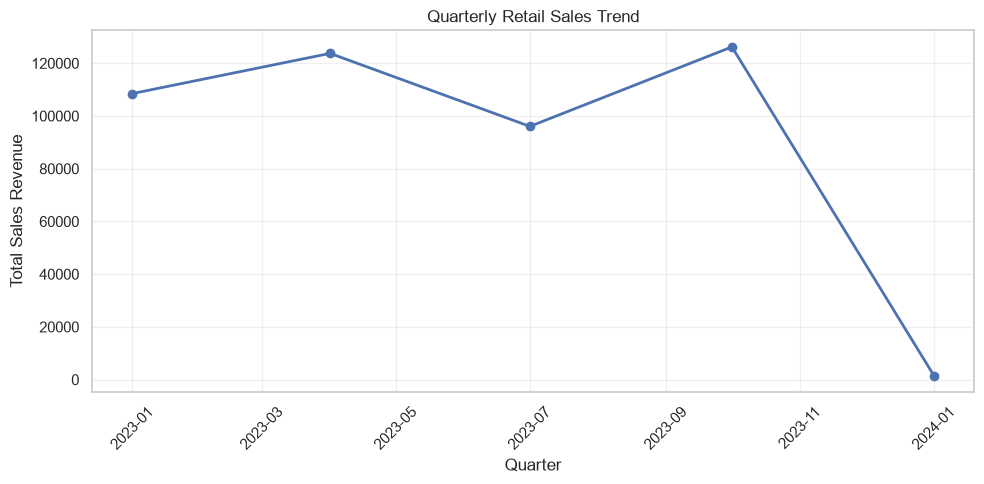

In [18]:
plt.figure(figsize=(10, 5))

plt.plot(
    quarterly_sales.index,
    quarterly_sales.values,
    marker="o",
    linewidth=2
)

plt.title("Quarterly Retail Sales Trend")
plt.xlabel("Quarter")
plt.ylabel("Total Sales Revenue")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

### Observation: Quarterly Sales Trend

Quarterly sales varied across the observed period. The highest-performing quarter was [quarter], while the lowest-performing quarter was [quarter].

Recommendation: Use quarterly sales patterns to improve inventory planning and schedule promotions during slower periods.

In [19]:
# Create customer age groups
bins = [18, 25, 35, 45, 55, 65]
labels = ["18-25", "26-35", "36-45", "46-55", "56-64"]

df["Age Group"] = pd.cut(
    df["Age"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Count customers in each age group
age_distribution = df["Age Group"].value_counts().sort_index()

display(age_distribution)

Age Group
18-25    169
26-35    205
36-45    202
46-55    229
56-64    195
Name: count, dtype: int64

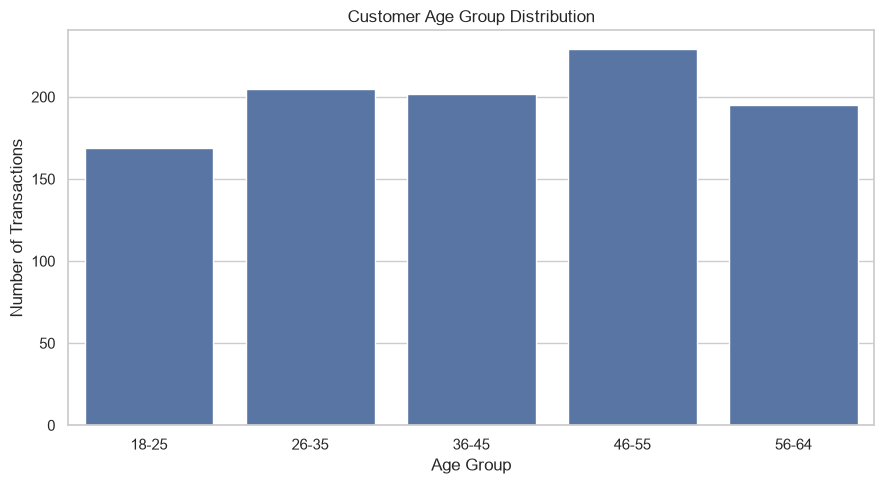

In [20]:
plt.figure(figsize=(9, 5))

sns.countplot(data=df, x="Age Group")

plt.title("Customer Age Group Distribution")
plt.xlabel("Age Group")
plt.ylabel("Number of Transactions")
plt.tight_layout()

plt.show()

In [21]:
gender_counts = df["Gender"].value_counts()

display(gender_counts)

Gender
Female    510
Male      490
Name: count, dtype: int64

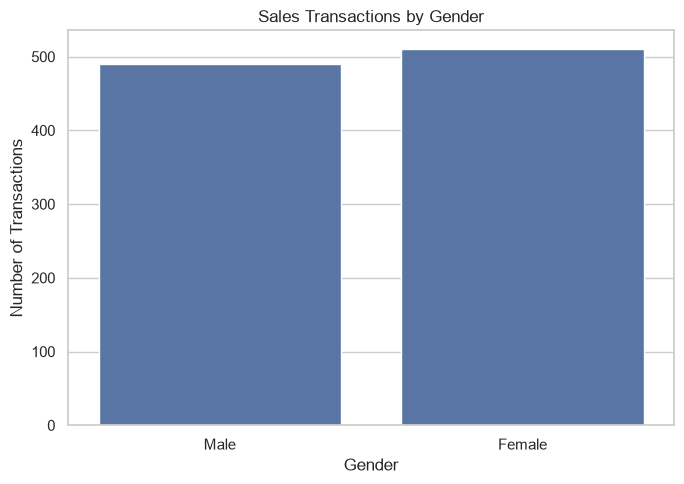

In [22]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Gender")

plt.title("Sales Transactions by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

### Observation: Customer Demographics

The age-group chart shows that [age group] accounts for the most transactions. The gender chart shows that [gender] has more transactions.

Recommendation: Use these demographic patterns to plan targeted marketing campaigns and product promotions.

In [23]:
# Total units sold by product category
top_categories = (
    df.groupby("Product Category")["Quantity"]
      .sum()
      .sort_values(ascending=False)
)

display(top_categories.head(10))

Product Category
Clothing       894
Electronics    849
Beauty         771
Name: Quantity, dtype: int64

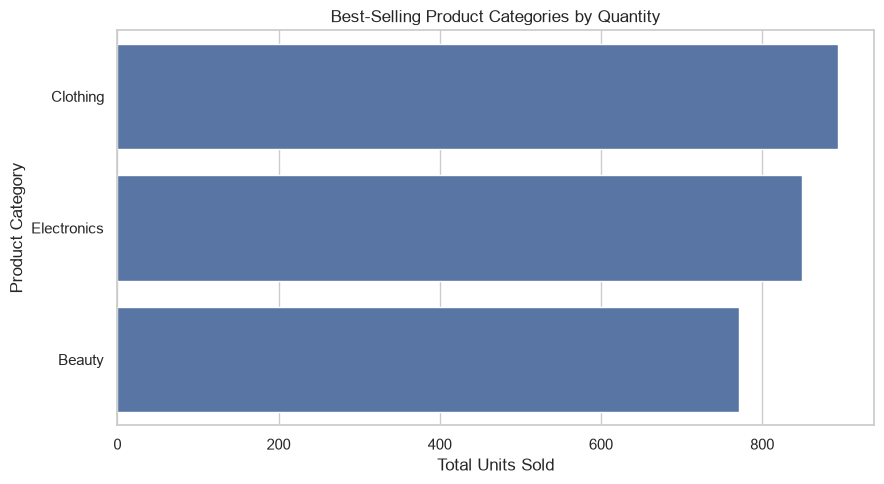

In [24]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=top_categories.values,
    y=top_categories.index
)

plt.title("Best-Selling Product Categories by Quantity")
plt.xlabel("Total Units Sold")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()

In [25]:
category_revenue = (
    df.groupby("Product Category")["Total Amount"]
      .sum()
      .sort_values(ascending=False)
)

display(category_revenue)

Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64

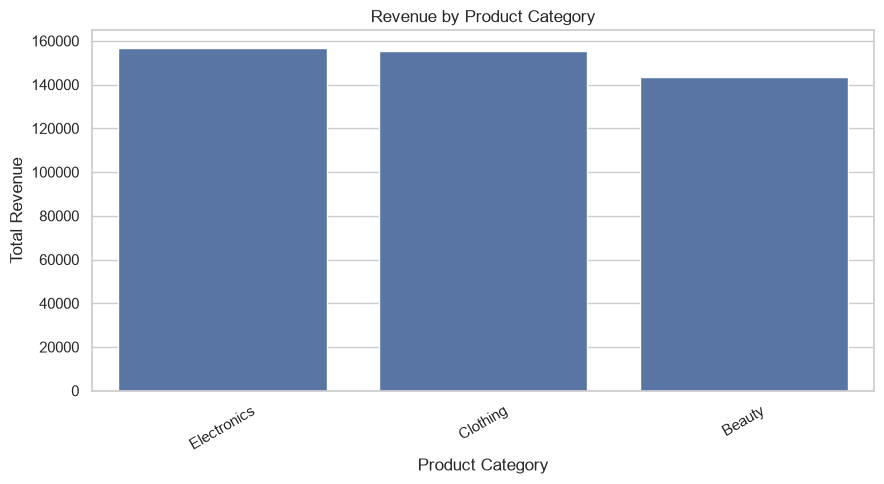

In [26]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=category_revenue.index,
    y=category_revenue.values
)

plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

### Observation: Product Analysis

The product category analysis identifies the categories contributing the most units sold and revenue.

Recommendations:
1. Maintain sufficient inventory for high-performing categories.
2. Investigate low-revenue categories to identify improvement opportunities.
3. Use category-level sales trends to guide promotions and inventory planning.

In [27]:
# Select numerical columns, excluding Transaction ID
numerical_df = df.select_dtypes(include="number").drop(
    columns=["Transaction ID"],
    errors="ignore"
)

# Calculate correlation
correlation_matrix = numerical_df.corr()

display(correlation_matrix.round(2))

,Age,Quantity,Price per Unit,Total Amount
Age,1.00,-0.02,-0.04,-0.06
Quantity,-0.02,1.00,0.02,0.37
Price per Unit,-0.04,0.02,1.00,0.85
Total Amount,-0.06,0.37,0.85,1.00


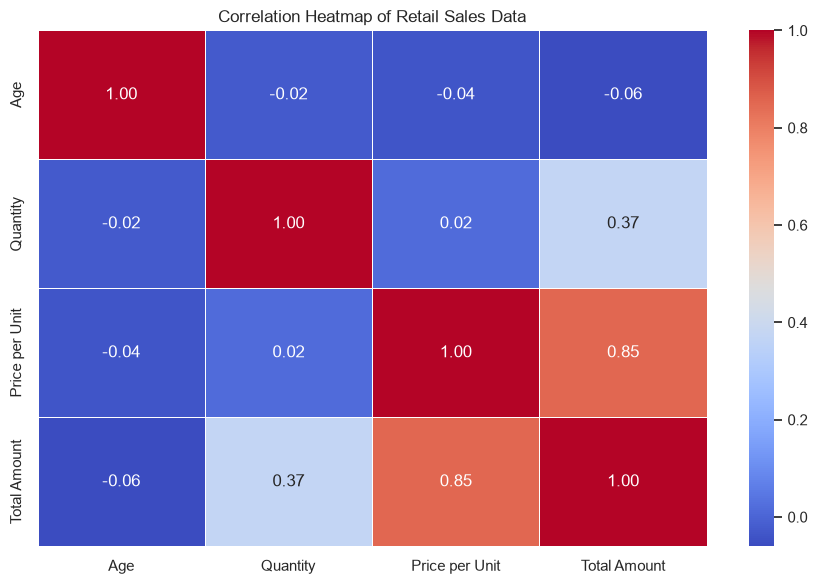

In [28]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Retail Sales Data")
plt.tight_layout()
plt.show()

### Observation: Correlation Analysis

The correlation heatmap shows the relationships between numerical variables in the retail sales dataset.

- **Price per Unit and Total Amount (0.85):** A strong positive correlation. Higher-priced items tend to have higher total transaction amounts.
- **Quantity and Total Amount (0.37):** A moderate positive correlation. Transactions with larger quantities generally have higher total amounts.
- **Age and Total Amount (-0.06):** A very weak negative correlation, indicating almost no linear relationship between age and total transaction amount.

**Recommendation:** Use transaction value and quantity patterns to support sales planning and product pricing decisions. Since age has almost no linear correlation with total transaction amount, explore customer age groups separately before making marketing decisions.

### Observation: Correlation Analysis

The correlation heatmap shows the relationships between numerical variables in the retail sales dataset.

- **Price per Unit and Total Amount (0.85):** A strong positive correlation. Higher-priced items tend to have higher total transaction amounts.
- **Quantity and Total Amount (0.37):** A moderate positive correlation. Transactions with larger quantities generally have higher total amounts.
- **Age and Total Amount (-0.06):** A very weak negative correlation, indicating almost no linear relationship between age and total transaction amount.

**Recommendation:** Use transaction value and quantity patterns to support sales planning and product pricing decisions. Since age has almost no linear correlation with total transaction amount, explore customer age groups separately before making marketing decisions.

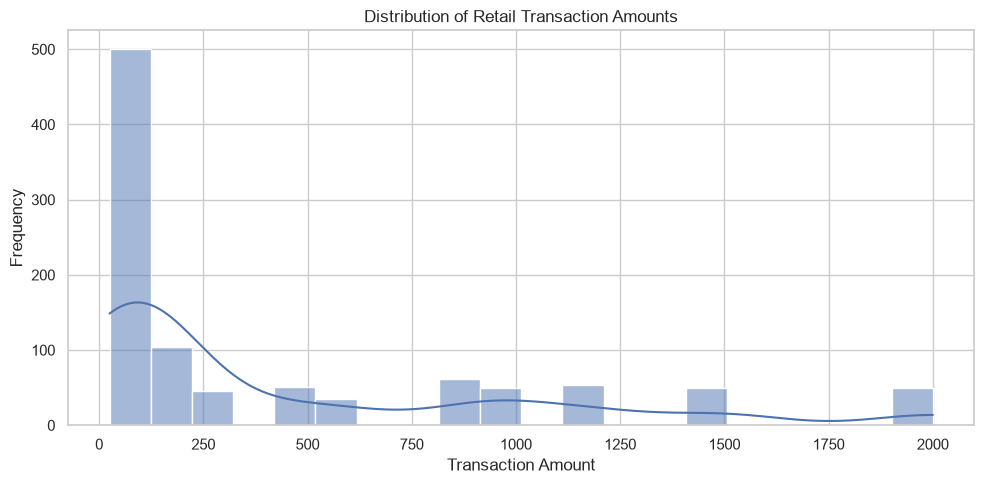

In [29]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Total Amount",
    bins=20,
    kde=True
)

plt.title("Distribution of Retail Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [30]:
mean_amount = df["Total Amount"].mean()
median_amount = df["Total Amount"].median()

print(f"Average transaction amount: {mean_amount:.2f}")
print(f"Median transaction amount: {median_amount:.2f}")

Average transaction amount: 456.00
Median transaction amount: 135.00


### Observation: Transaction Amount Distribution

The transaction amount distribution shows how customer spending varies across purchases. The average transaction amount is [mean], while the median is [median].

Recommendation: Use transaction value patterns to design suitable promotions and encourage customers to make additional purchases.



### Key Insights
- Sales Trends:Monthly and quarterly analysis revealed variations in sales revenue.
- Customer Demographics: Age and gender analysis helped understand customer transaction patterns.
- Product Performance: Category analysis identified differences in sales volume and revenue.
- Customer Spending: Transaction analysis highlighted variations in purchase amounts.

### Business Recommendations
1. Inventory Management: Maintain sufficient stock of high-performing categories.
2. Targeted Marketing: Design campaigns based on customer demographics and purchasing patterns.
3. Sales Improvement:Investigate low-performing months and introduce suitable promotions.
4. Performance Monitoring: Track sales trends regularly to support business decisions.

### Conclusion
EDA helped identify patterns in sales, customer demographics, product categories, and spending behavior. These findings can support better inventory planning, marketing strategies, and revenue growth.